# **Insurance Data Protection — Linear Algebra & Machine Learning**

**Projeto de Álgebra Linear | Python · NumPy · Pandas · scikit-learn**

## **Introdução**

Este projeto investiga aplicações de Álgebra Linear e Aprendizado de Máquina em um cenário de seguros. A base contém informações de 5.000 clientes, incluindo gênero, idade, renda, número de familiares e quantidade de benefícios de seguro recebidos nos últimos cinco anos.

O trabalho está organizado em quatro frentes complementares: identificação de clientes semelhantes por meio do algoritmo k-Nearest Neighbors (kNN); classificação da ocorrência de benefícios como exercício complementar presente no notebook do curso; previsão do número de benefícios com regressão linear; e avaliação de uma transformação matricial para ofuscar atributos pessoais sem alterar as previsões da regressão linear.

**Objetivo principal:** demonstrar como operações com vetores e matrizes sustentam algoritmos de aprendizado de máquina e como uma transformação linear invertível pode alterar a representação dos dados sem prejudicar as previsões de um modelo de regressão linear.

## **Roteiro**

1. Carregamento e inspeção dos dados.
2. Análise exploratória e preparação das variáveis.
3. Tarefa 1 — busca de clientes semelhantes com kNN.
4. Tarefa 2 — classificação da ocorrência de benefícios com kNN e comparação com um baseline.
5. Tarefa 3 — regressão linear para prever a quantidade de benefícios.
6. Tarefa 4 — ofuscação por transformação matricial e validação matemática e computacional.
7. Conclusões e limitações.

# **1. Bibliotecas e configuração**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MaxAbsScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    f1_score, confusion_matrix, classification_report,
    mean_squared_error, r2_score
)

from IPython.display import display

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

# **2. Carregamento e inspeção dos dados**

Faça o upload do arquivo `insurance_us.csv` no Google Colab. O notebook também pode ser executado localmente, desde que o CSV esteja no mesmo diretório.

In [3]:
# Google Colab: selecione insurance_us.csv na janela de upload.
try:
    from google.colab import files
    uploaded = files.upload()
    data_file = "insurance_us.csv"
except ImportError:
    data_file = "insurance_us.csv"

df = pd.read_csv(data_file)

df = df.rename(columns={
    "Gender": "gender",
    "Age": "age",
    "Salary": "income",
    "Family members": "family_members",
    "Insurance benefits": "insurance_benefits"
})

print(f"Dimensões da base: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
display(df.head())

Saving insurance_us.csv to insurance_us (1).csv
Dimensões da base: 5,000 linhas × 5 colunas


,gender,age,income,family_members,insurance_benefits
0,1,41.000,"49,600.000",1,0
1,0,46.000,"38,000.000",1,1
2,0,29.000,"21,000.000",0,0
3,0,21.000,"41,700.000",2,0
4,1,28.000,"26,100.000",0,0


### **2.1 Estrutura, tipos e valores ausentes**

In [4]:
df.info()
display(df.isna().sum().to_frame("missing_values"))
print(f"Registros duplicados: {df.duplicated().sum():,}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   float64
 2   income              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


,missing_values
gender,0
age,0
income,0
family_members,0
insurance_benefits,0


Registros duplicados: 153


A base contém cinco variáveis: quatro características dos clientes e uma variável-alvo (`insurance_benefits`). A inspeção de tipos e valores ausentes permite identificar necessidades de preparação antes da modelagem. Registros duplicados são verificados, mas não devem ser removidos automaticamente sem avaliar se representam duplicações reais.

### **2.2 Estatísticas descritivas e validação**

In [5]:
display(df.describe().T)
display(df.nunique().to_frame("unique_values"))

,count,mean,std,min,25%,50%,75%,max
gender,"5,000.000",0.499,0.500,0.000,0.000,0.000,1.000,1.000
age,"5,000.000",30.953,8.441,18.000,24.000,30.000,37.000,65.000
income,"5,000.000","39,916.360","9,900.084","5,300.000","33,300.000","40,200.000","46,600.000","79,000.000"
family_members,"5,000.000",1.194,1.091,0.000,0.000,1.000,2.000,6.000
insurance_benefits,"5,000.000",0.148,0.463,0.000,0.000,0.000,0.000,5.000


,unique_values
gender,2
age,46
income,524
family_members,7
insurance_benefits,6


In [6]:
# Verificações de domínio e consistência
validation = {
    "gender_values": sorted(df["gender"].dropna().unique().tolist()),
    "negative_age": int((df["age"] < 0).sum()),
    "negative_income": int((df["income"] < 0).sum()),
    "negative_family_members": int((df["family_members"] < 0).sum()),
    "negative_benefits": int((df["insurance_benefits"] < 0).sum()),
    "non_integer_age": int((df["age"] % 1 != 0).sum()),
    "non_integer_family_members": int((df["family_members"] % 1 != 0).sum()),
    "non_integer_benefits": int((df["insurance_benefits"] % 1 != 0).sum())
}
display(pd.Series(validation, name="result").to_frame())

,result
gender_values,"[0, 1]"
negative_age,0
negative_income,0
negative_family_members,0
negative_benefits,0
non_integer_age,0
non_integer_family_members,0
non_integer_benefits,0


A tabela de estatísticas descritivas resume a distribuição das variáveis e ajuda a identificar valores fora do domínio esperado. A variável `gender` é codificada numericamente; `age`, `family_members` e `insurance_benefits` representam contagens ou quantidades inteiras. A renda é uma variável numérica contínua.

A inspeção desta base identifica 153 linhas exatamente duplicadas. Como o conjunto não possui um identificador individual que permita confirmar se são duplicações indevidas ou registros legítimos com os mesmos atributos, elas são mantidas nesta versão; essa decisão evita excluir observações sem evidência suficiente.\n\nValores extremos não devem ser excluídos apenas por serem distantes da média: em uma base de seguros, rendas elevadas podem ser legítimas. A decisão de tratamento deve considerar regras de negócio e evidências de erro.

### **2.3 Preparação das variáveis**

In [7]:
# Converter variáveis que representam contagens para inteiros,
# após confirmar que não existem valores ausentes ou fracionários.
count_columns = ["age", "family_members", "insurance_benefits"]

for column in count_columns:
    if df[column].isna().any():
        raise ValueError(f"A coluna {column} contém valores ausentes.")
    if not np.allclose(df[column] % 1, 0):
        raise ValueError(f"A coluna {column} contém valores fracionários.")
    df[column] = df[column].astype("int64")

print(df.dtypes)

gender                  int64
age                     int64
income                float64
family_members          int64
insurance_benefits      int64
dtype: object


A conversão para inteiro é aplicada às variáveis que representam quantidades discretas, depois de verificar a ausência de valores ausentes e de partes fracionárias. Nenhuma observação é removida ou imputada nesta etapa, pois a inspeção da base deve orientar qualquer tratamento adicional.

### **2.4 Distribuições das características**

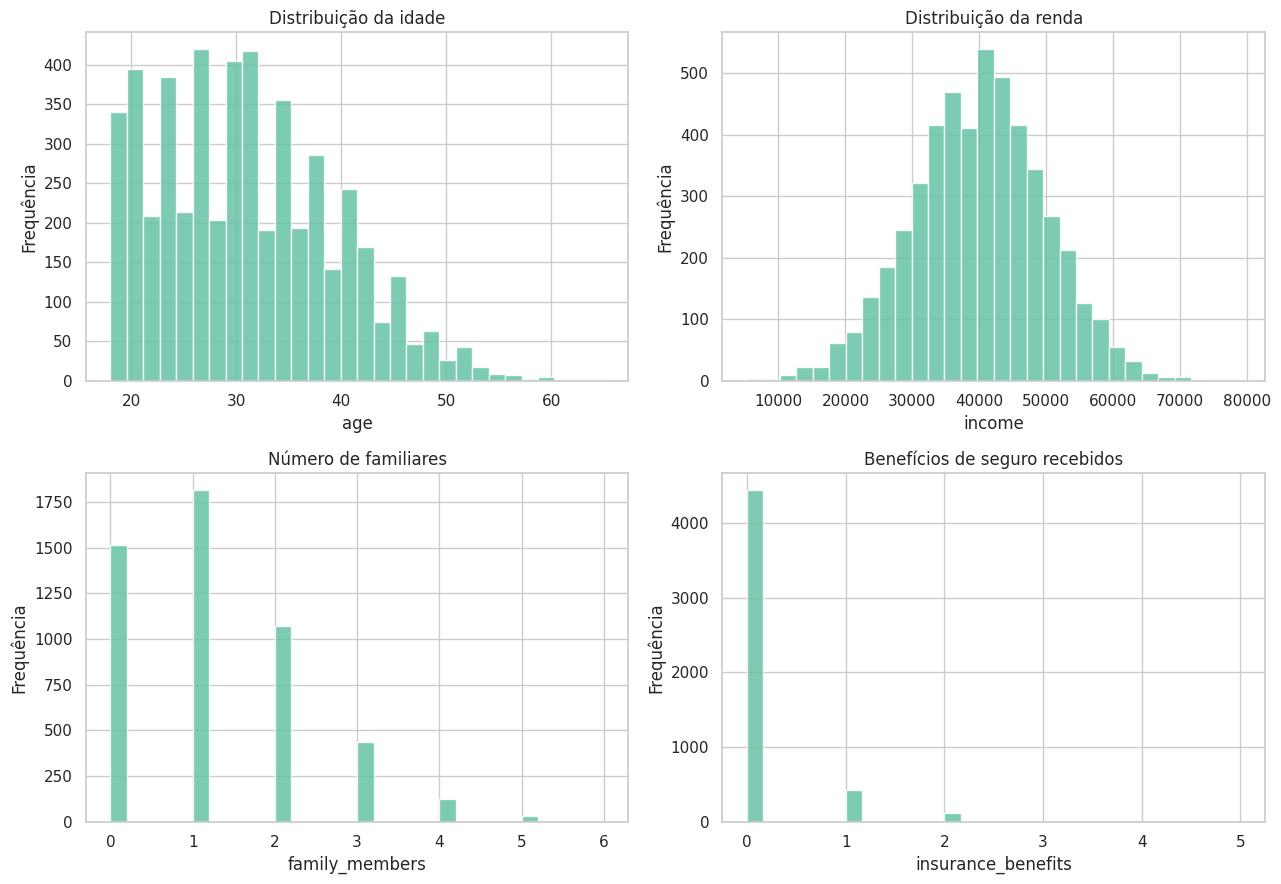

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_columns = [
    ("age", "Distribuição da idade"),
    ("income", "Distribuição da renda"),
    ("family_members", "Número de familiares"),
    ("insurance_benefits", "Benefícios de seguro recebidos")
]

for ax, (column, title) in zip(axes.flat, plot_columns):
    ax.hist(df[column], bins=30, edgecolor="white", alpha=0.85)
    ax.set_title(title)
    ax.set_xlabel(column)
    ax.set_ylabel("Frequência")

plt.tight_layout()
plt.show()

As distribuições permitem observar concentração, assimetria e amplitude das variáveis. A renda possui escala numérica muito maior do que as demais características; essa diferença é especialmente relevante para métodos baseados em distância, como kNN. Por isso, a análise de similaridade será comparada antes e depois do escalonamento.

# **3. Tarefa 1 — Identificação de clientes semelhantes**

O objetivo é recuperar os *k* clientes mais próximos de um cliente de referência. A variável-alvo `insurance_benefits` não será utilizada nessa tarefa: a similaridade será calculada somente a partir de gênero, idade, renda e número de familiares.

In [9]:
feature_names = ["gender", "age", "income", "family_members"]

def get_knn(data, row_index, k=5, metric="euclidean"):
    """Retorna os k vizinhos mais próximos, incluindo o próprio registro de referência."""
    model = NearestNeighbors(n_neighbors=k, metric=metric)
    model.fit(data[feature_names])
    distances, indices = model.kneighbors(
        data.iloc[[row_index]][feature_names],
        return_distance=True
    )

    result = data.iloc[indices[0]].copy()
    result["distance"] = distances[0]
    result["row_index"] = indices[0]
    return result

reference_index = 0
k = 5

print("Amostra de referência:")
display(df.iloc[[reference_index]][feature_names + ["insurance_benefits"]])

Amostra de referência:


,gender,age,income,family_members,insurance_benefits
0,1,41,"49,600.000",1,0


### **3.1 Comparação sem escalonamento**

In [10]:
for metric in ["euclidean", "manhattan"]:
    print(f"Métrica: {metric}")
    display(get_knn(df, reference_index, k=k, metric=metric))

Métrica: euclidean


,gender,age,income,family_members,insurance_benefits,distance,row_index
0,1,41,"49,600.000",1,0,0.000,0
2022,1,41,"49,600.000",0,0,1.000,2022
1225,0,42,"49,600.000",0,1,1.732,1225
4031,1,44,"49,600.000",2,1,3.162,4031
3424,0,38,"49,600.000",0,0,3.317,3424


Métrica: manhattan


,gender,age,income,family_members,insurance_benefits,distance,row_index
0,1,41,"49,600.000",1,0,0.000,0
2022,1,41,"49,600.000",0,0,1.000,2022
1225,0,42,"49,600.000",0,1,3.000,1225
4031,1,44,"49,600.000",2,1,4.000,4031
3424,0,38,"49,600.000",0,0,5.000,3424


Sem escalonamento, a renda tende a dominar o cálculo das distâncias porque seus valores são numericamente muito maiores do que os das outras características. Assim, diferenças de renda podem ter peso desproporcional na seleção dos vizinhos, mesmo quando idade, gênero ou composição familiar também são relevantes.

### **3.2 Comparação com escalonamento**

In [11]:
scaler_knn = MaxAbsScaler()
df_scaled = df.copy()
df_scaled.loc[:, feature_names] = scaler_knn.fit_transform(df[feature_names])

for metric in ["euclidean", "manhattan"]:
    print(f"Métrica: {metric}")
    display(get_knn(df_scaled, reference_index, k=k, metric=metric))

Métrica: euclidean


/tmp/ipykernel_1072/1822304178.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.63076923 0.70769231 0.44615385 ... 0.30769231 0.33846154 0.43076923]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_scaled.loc[:, feature_names] = scaler_knn.fit_transform(df[feature_names])
/tmp/ipykernel_1072/1822304178.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.16666667 0.16666667 0.         ... 0.33333333 0.5        0.16666667]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_scaled.loc[:, feature_names] = scaler_knn.fit_transform(df[feature_names])


,gender,age,income,family_members,insurance_benefits,distance,row_index
0,1,0.631,0.628,0.167,0,0.000,0
2689,1,0.631,0.634,0.167,0,0.006,2689
133,1,0.615,0.637,0.167,0,0.018,133
4869,1,0.646,0.638,0.167,1,0.018,4869
3275,1,0.646,0.652,0.167,1,0.029,3275


Métrica: manhattan


,gender,age,income,family_members,insurance_benefits,distance,row_index
0,1,0.631,0.628,0.167,0,0.000,0
2689,1,0.631,0.634,0.167,0,0.006,2689
133,1,0.615,0.637,0.167,0,0.024,133
4869,1,0.646,0.638,0.167,1,0.026,4869
2103,1,0.631,0.596,0.167,0,0.032,2103


Após o escalonamento, as características passam a contribuir em escalas comparáveis para o cálculo das distâncias. A composição dos vizinhos pode mudar, pois o algoritmo deixa de ser dominado pela magnitude da renda. O MaxAbsScaler divide cada variável pelo seu valor absoluto máximo e preserva zeros, sendo uma das alternativas de escalonamento.

### **3.3 Respostas — Tarefa 1**

**Os dados não escalados afetam o algoritmo kNN?**

Sim. kNN utiliza distâncias entre observações. Quando as variáveis possuem escalas muito diferentes, a variável de maior magnitude pode dominar o cálculo. Neste conjunto, a renda possui valores muito superiores aos de gênero, idade e número de familiares. O escalonamento reduz esse efeito e torna a comparação entre características mais equilibrada.

**Os resultados de Manhattan e Euclidiana são semelhantes?**

As duas métricas medem proximidade de maneiras diferentes: a distância Euclidiana corresponde à distância em linha reta, enquanto a Manhattan soma diferenças absolutas por dimensão. Os vizinhos podem coincidir em alguns casos, mas não há garantia de equivalência. A comparação deve ser feita pelas tabelas produzidas para os dados escalados e não escalados.

# **4. Tarefa 2 — Classificação da ocorrência de benefícios**

Esta etapa complementar, presente no notebook do curso, transforma a variável-alvo em uma classificação binária: 1 quando o cliente recebeu pelo menos um benefício e 0 quando não recebeu. O desempenho do kNN será comparado com um classificador baseline (*DummyClassifier*).

Como a classe positiva pode ser minoritária, a métrica F1 é mais informativa do que a acurácia isolada.

In [12]:
df["benefit_received"] = (df["insurance_benefits"] > 0).astype(int)
display(df["benefit_received"].value_counts().rename("count").to_frame())
display((df["benefit_received"].value_counts(normalize=True) * 100).rename("percentage").to_frame())

,count
benefit_received,
0,4436
1,564


,percentage
benefit_received,
0,88.720
1,11.280


### **4.1 Divisão treino e teste**

In [13]:
X_cls = df[feature_names]
y_cls = df["benefit_received"]

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.30, random_state=RANDOM_STATE, stratify=y_cls
)

print("Distribuição no treino:")
display(y_train_cls.value_counts(normalize=True).rename("proportion").to_frame())
print("Distribuição no teste:")
display(y_test_cls.value_counts(normalize=True).rename("proportion").to_frame())

Distribuição no treino:


,proportion
benefit_received,
0,0.887
1,0.113


Distribuição no teste:


,proportion
benefit_received,
0,0.887
1,0.113


A divisão estratificada mantém aproximadamente a mesma proporção de classes nos conjuntos de treino e teste. O conjunto de teste fica reservado para avaliação final; o escalonador será ajustado apenas nos dados de treino para evitar vazamento de informação.

### **4.2 Baseline e kNN**

In [14]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_cls, y_train_cls)
dummy_pred = dummy.predict(X_test_cls)
dummy_f1 = f1_score(y_test_cls, dummy_pred, zero_division=0)

scaler_cls = MaxAbsScaler()
X_train_cls_scaled = scaler_cls.fit_transform(X_train_cls)
X_test_cls_scaled = scaler_cls.transform(X_test_cls)

classification_results = []
for k_value in range(1, 11):
    knn = KNeighborsClassifier(n_neighbors=k_value)
    knn.fit(X_train_cls_scaled, y_train_cls)
    predictions = knn.predict(X_test_cls_scaled)
    classification_results.append({
        "k": k_value,
        "F1": f1_score(y_test_cls, predictions, zero_division=0)
    })

classification_results = pd.DataFrame(classification_results)
print(f"F1 baseline: {dummy_f1:.4f}")
display(classification_results)

F1 baseline: 0.0000


,k,F1
0,1,0.910
1,2,0.915
2,3,0.935
3,4,0.890
4,5,0.915
5,6,0.892
6,7,0.921
7,8,0.893
8,9,0.924
9,10,0.892


Melhor k no intervalo avaliado: 3
F1 do kNN: 0.9354

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1331
           1       0.97      0.90      0.94       169

    accuracy                           0.99      1500
   macro avg       0.98      0.95      0.96      1500
weighted avg       0.99      0.99      0.99      1500



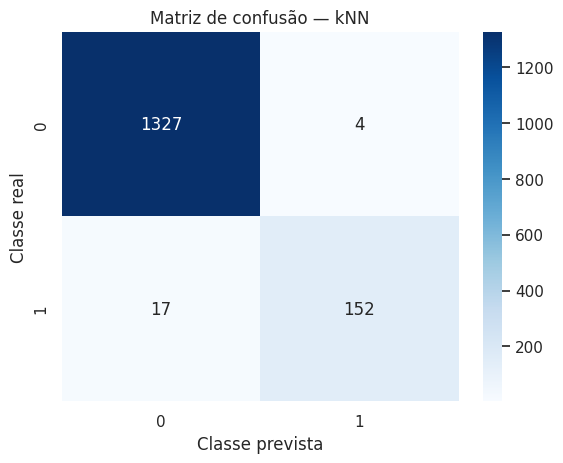

In [15]:
best_k = int(classification_results.loc[classification_results["F1"].idxmax(), "k"])
best_knn_cls = KNeighborsClassifier(n_neighbors=best_k)
best_knn_cls.fit(X_train_cls_scaled, y_train_cls)
best_cls_pred = best_knn_cls.predict(X_test_cls_scaled)

print(f"Melhor k no intervalo avaliado: {best_k}")
print(f"F1 do kNN: {f1_score(y_test_cls, best_cls_pred):.4f}")
print("\nRelatório de classificação:")
print(classification_report(y_test_cls, best_cls_pred, zero_division=0))

cm = confusion_matrix(y_test_cls, best_cls_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de confusão — kNN")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

**Interpretação:** o baseline que sempre prevê a classe majoritária estabelece uma referência mínima. O kNN deve ser comparado a esse resultado pela métrica F1 e pela matriz de confusão. Um F1 maior indica melhor equilíbrio entre precisão e revocação para a classe positiva. O melhor valor de *k* encontrado neste intervalo é uma escolha exploratória, não uma otimização exaustiva.

# **5. Tarefa 3 — Regressão linear para prever benefícios**

Nesta tarefa, o alvo é a quantidade de benefícios recebidos (`insurance_benefits`), e não apenas a ocorrência de pelo menos um benefício. Será implementada a regressão linear usando a formulação matricial dos mínimos quadrados. A divisão treino/teste será mantida igual para comparar os dados originais e escalados.

In [16]:
X_reg = df[feature_names].to_numpy(dtype=float)
y_reg = df["insurance_benefits"].to_numpy(dtype=float)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.30, random_state=RANDOM_STATE
)

print("Dimensões do treino:", X_train_reg.shape)
print("Dimensões do teste:", X_test_reg.shape)

Dimensões do treino: (3500, 4)
Dimensões do teste: (1500, 4)


### **5.1 Implementação matricial da regressão linear**

In [17]:
class MyLinearRegression:
    """Regressão linear por mínimos quadrados, com intercepto."""

    def __init__(self):
        self.weights = None

    def fit(self, X, y):
        X_with_intercept = np.column_stack([np.ones(X.shape[0]), X])
        # lstsq calcula a solução de mínimos quadrados sem exigir inversão explícita.
        self.weights = np.linalg.lstsq(X_with_intercept, y, rcond=None)[0]
        return self

    def predict(self, X):
        X_with_intercept = np.column_stack([np.ones(X.shape[0]), X])
        return X_with_intercept @ self.weights

def evaluate_regression(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"RMSE": rmse, "R2": r2}

### **5.2 Modelo com características originais**

In [18]:
linear_original = MyLinearRegression().fit(X_train_reg, y_train_reg)
pred_original = linear_original.predict(X_test_reg)
metrics_original = evaluate_regression(y_test_reg, pred_original)

display(pd.DataFrame([metrics_original], index=["Dados originais"]))

,RMSE,R2
Dados originais,0.364,0.423


### **5.3 Modelo com características escaladas**

In [19]:
scaler_reg = MaxAbsScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

linear_scaled = MyLinearRegression().fit(X_train_reg_scaled, y_train_reg)
pred_scaled = linear_scaled.predict(X_test_reg_scaled)
metrics_scaled = evaluate_regression(y_test_reg, pred_scaled)

regression_comparison = pd.DataFrame(
    [metrics_original, metrics_scaled],
    index=["Dados originais", "Dados escalados"]
)
display(regression_comparison)

,RMSE,R2
Dados originais,0.364,0.423
Dados escalados,0.364,0.423


A regressão linear ajusta os coeficientes para minimizar a soma dos erros quadráticos. O escalonamento pode alterar a escala dos coeficientes, mas não deve modificar substancialmente as previsões quando a transformação é uma reescala invertível das características e o modelo inclui intercepto. Pequenas diferenças numéricas podem ocorrer devido à precisão computacional.

# **6. Tarefa 4 — Ofuscação de dados por transformação matricial**

A proposta é multiplicar a matriz de características por uma matriz quadrada invertível \(P\):

\[
X' = XP
\]

A transformação produz novas combinações lineares das características originais. Sem conhecer \(P\), a interpretação direta das colunas transformadas fica dificultada. Se \(P\) for invertível e conhecida, os dados podem ser recuperados por \(X = X'P^{-1}\).

**Nota de segurança:** esta transformação é uma demonstração de ofuscação matemática. Não substitui criptografia, controle de acesso, anonimização formal ou outras medidas de segurança da informação.

### **6.1 Construção e verificação da matriz**

In [20]:
X = df[feature_names].to_numpy(dtype=float)
rng = np.random.default_rng(RANDOM_STATE)

while True:
    P = rng.normal(size=(X.shape[1], X.shape[1]))
    if np.linalg.matrix_rank(P) == X.shape[1]:
        break

det_P = np.linalg.det(P)
print("Matriz P:")
display(pd.DataFrame(P))
print(f"Determinante de P: {det_P:.8f}")
print(f"Posto de P: {np.linalg.matrix_rank(P)}")

Matriz P:


,0,1,2,3
0,0.305,-1.040,0.750,0.941
1,-1.951,-1.302,0.128,-0.316
2,-0.017,-0.853,0.879,0.778
3,0.066,1.127,0.468,-0.859


Determinante de P: 0.57217362
Posto de P: 4


A matriz \(P\) é quadrada e possui posto completo. Portanto, é invertível. O uso de uma matriz aleatória com distribuição normal reduz o risco de gerar uma matriz numericamente mal condicionada em comparação com escolhas arbitrárias. O determinante diferente de zero é uma condição equivalente à invertibilidade para matrizes quadradas.

### **6.2 Aplicação da transformação e recuperação**

In [21]:
X_obfuscated = X @ P
P_inverse = np.linalg.inv(P)
X_recovered = X_obfuscated @ P_inverse

print("Primeiros registros — dados originais:")
display(pd.DataFrame(X[:5], columns=feature_names))

print("Primeiros registros — dados ofuscados:")
display(pd.DataFrame(X_obfuscated[:5], columns=[f"transformed_{i+1}" for i in range(X.shape[1])]))

print("Primeiros registros — dados recuperados:")
display(pd.DataFrame(X_recovered[:5], columns=feature_names))

print("Recuperação numericamente equivalente:", np.allclose(X, X_recovered))
print("Maior erro absoluto de recuperação:", np.max(np.abs(X - X_recovered)))

Primeiros registros — dados originais:


,gender,age,income,family_members
0,1.000,41.000,"49,600.000",1.000
1,0.000,46.000,"38,000.000",1.000
2,0.000,29.000,"21,000.000",0.000
3,0.000,21.000,"41,700.000",2.000
4,1.000,28.000,"26,100.000",0.000


Primeiros registros — dados ofuscados:


,transformed_1,transformed_2,transformed_3,transformed_4
0,-912.959,"-42,364.281","43,624.599","38,565.595"
1,-728.126,"-32,474.442","33,423.471","29,540.687"
2,-409.404,"-17,951.686","18,471.065","16,324.460"
3,-741.448,"-35,597.023","36,674.515","32,425.564"
4,-492.834,"-22,301.948","22,956.617","20,292.455"


Primeiros registros — dados recuperados:


,gender,age,income,family_members
0,1.000,41.000,"49,600.000",1.000
1,-0.000,46.000,"38,000.000",1.000
2,-0.000,29.000,"21,000.000",-0.000
3,-0.000,21.000,"41,700.000",2.000
4,1.000,28.000,"26,100.000",-0.000


Recuperação numericamente equivalente: True
Maior erro absoluto de recuperação: 9.976498019146622e-11


Os valores transformados são combinações lineares das quatro características e deixam de corresponder diretamente a idade, renda ou número de familiares. Ao multiplicar pela inversa de \(P\), a matriz original é recuperada. A função `np.allclose` verifica equivalência dentro de uma tolerância numérica, pois operações em ponto flutuante podem produzir pequenas diferenças de arredondamento.

### **6.3 Prova analítica da preservação das previsões**

Considere a solução de mínimos quadrados da regressão linear sem intercepto explícito na notação matricial:

\[
w = (X^T X)^{-1}X^T y
\]

Após a transformação \(X' = XP\), com \(P\) invertível, os novos coeficientes são:

\[
\begin{aligned}
w_P &= [(XP)^T(XP)]^{-1}(XP)^T y \\
&= [P^T X^T X P]^{-1}P^T X^T y \\
&= P^{-1}(X^T X)^{-1}(P^T)^{-1}P^T X^T y \\
&= P^{-1}(X^T X)^{-1}X^T y \\
&= P^{-1}w
\end{aligned}
\]

Logo, as previsões no espaço transformado são:

\[
\hat{y}_P = X'w_P = XP P^{-1}w = Xw = \hat{y}
\]

Portanto, as previsões permanecem iguais e, consequentemente, métricas calculadas a partir delas, como RMSE e \(R^2\), também permanecem iguais.

**Observação:** a demonstração acima usa a forma sem intercepto para simplificar a álgebra. Quando o modelo inclui intercepto, a transformação é aplicada somente às colunas de características e a coluna de intercepto é mantida separadamente; o mesmo resultado é preservado.

### **6.4 Validação computacional com regressão linear**

In [22]:
# Reutilizar a mesma divisão treino/teste da tarefa de regressão.
# Aplicar a mesma matriz P às características de treino e teste.
X_train_obf = X_train_reg @ P
X_test_obf = X_test_reg @ P

linear_obfuscated = MyLinearRegression().fit(X_train_obf, y_train_reg)
pred_obfuscated = linear_obfuscated.predict(X_test_obf)
metrics_obfuscated = evaluate_regression(y_test_reg, pred_obfuscated)

obfuscation_comparison = pd.DataFrame(
    [metrics_original, metrics_obfuscated],
    index=["Características originais", "Características ofuscadas"]
)
display(obfuscation_comparison)

print("Previsões numericamente equivalentes:",
      np.allclose(pred_original, pred_obfuscated, rtol=1e-7, atol=1e-7))
print("Maior diferença absoluta entre previsões:",
      np.max(np.abs(pred_original - pred_obfuscated)))

,RMSE,R2
Características originais,0.364,0.423
Características ofuscadas,0.364,0.423


Previsões numericamente equivalentes: True
Maior diferença absoluta entre previsões: 7.063932772055637e-13


A comparação utiliza a mesma partição de treino e teste, o mesmo alvo e a mesma implementação de regressão. A matriz \(P\) é aplicada tanto ao conjunto de treino quanto ao de teste. Se as previsões forem numericamente equivalentes, RMSE e \(R^2\) também deverão coincidir dentro da tolerância computacional. Essa verificação confirma, na implementação, a propriedade demonstrada analiticamente.

# **7. Conclusão geral**

O projeto demonstrou aplicações de Álgebra Linear em diferentes etapas de um fluxo de aprendizado de máquina.

Na identificação de clientes semelhantes, o kNN evidenciou a importância do escalonamento: variáveis com magnitudes maiores podem dominar as distâncias e alterar a seleção dos vizinhos. A comparação entre as métricas Euclidiana e Manhattan mostrou que a definição de distância também influencia o resultado.

Na classificação binária complementar, o desempenho do kNN foi comparado a um baseline pela métrica F1, considerando o possível desbalanceamento da variável-alvo. Na regressão, foi implementado o método dos mínimos quadrados em notação matricial e avaliadas as previsões por RMSE e \(R^2\), com características originais e escaladas.

Por fim, a ofuscação foi implementada por meio da multiplicação das características por uma matriz invertível. A recuperação com a matriz inversa confirmou a reversibilidade da transformação quando \(P\) é conhecida. A demonstração analítica e a validação computacional verificaram que as previsões da regressão linear podem ser preservadas após a transformação.

Em conjunto, os resultados mostram como vetores, matrizes, distâncias e operações matriciais sustentam algoritmos de aprendizado de máquina. Também evidenciam que a ofuscação apresentada é uma técnica matemática de transformação de dados, mas não deve ser confundida com um mecanismo completo de segurança ou anonimização.

# **8. Limitações e considerações**

- A busca de vizinhos depende da métrica de distância e do escalonamento escolhido.
- O melhor valor de \(k\) na classificação foi avaliado em um intervalo limitado; uma busca mais ampla e validação cruzada poderiam aprofundar a seleção.
- A regressão linear pode produzir previsões fracionárias ou negativas para um alvo de contagem; isso deve ser considerado ao interpretar seu uso prático.
- A matriz invertível não torna os dados irreversivelmente anônimos. Quem tiver acesso à matriz \(P\) e à transformação poderá recuperar as características.
- A preservação matemática das previsões depende das condições da transformação e do ajuste do modelo; pequenas diferenças numéricas podem ocorrer na prática.

Esses pontos delimitam o alcance das conclusões e evitam interpretar a ofuscação como substituta de controles de segurança apropriados.